# Clustering II (Linkage / Hierarchical)

Hierarchical Clustering adalah metode *unsupervised learning* yang membangun sebuah hierarki atau struktur pohon dari cluster, berbeda dengan K-Means yang membutuhkan jumlah cluster (K) ditentukan di awal.

Ada dua pendekatan utama:
- **Agglomerative** (bottom-up): setiap titik data dimulai sebagai cluster individual, lalu pasangan cluster terdekat digabungkan secara beruntun.
- **Divisive** (top-down): dimulai dari satu cluster besar, lalu dipecah rekursif jadi cluster lebih kecil.

Kunci dari Agglomerative Clustering adalah **linkage criteria** — cara mengukur jarak antar cluster (bukan antar titik): *Single*, *Complete*, *Average*, dan *Ward* (default di sklearn).

**Dendrogram** adalah diagram pohon yang merekam urutan penggabungan cluster; dengan "memotong" dendrogram di ketinggian tertentu, kita bisa menentukan jumlah cluster.

**Cophenetic Correlation Coefficient** adalah metrik yang mengukur seberapa setia dendrogram merepresentasikan jarak asli antar sampel — pelengkap Silhouette Score untuk mengevaluasi kualitas struktur pohonnya, bukan hanya hasil potongannya.

### 1.1 Install Library

In [9]:
#pip install numpy pandas scikit-learn scipy matplotlib seaborn

### 1.2 Import Library yang Dibutuhkan

In [10]:
import numpy as np
import pandas as pf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_iris
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage, cophenet
from scipy.spatial.distance import pdist

### 1.3 Mempersiapkan Dataset
Pertemuan ini menggunakan dataset dari scikit-learn, yaitu dataset **Iris** (150 sampel, 4 fitur) — sama seperti Modul 4.
- #### 1.3.1 Import Dataset

In [24]:
df = load_iris(as_frame=True)
x = df.data
y = df.target

display(x.head())
print(x.describe())
print(x.info())
display(y)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)  
count        150.000000  
mean           1.199333  
std            0.762238  
min            0.100000  
25%            0.300000  
50%            1.300000  
75%            1.800000  
max            2.500000  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             ----

0      0
1      0
2      0
3      0
4      0
      ..
145    2
146    2
147    2
148    2
149    2
Name: target, Length: 150, dtype: int64

- #### 1.3.2 Standardisasi Data
Sama seperti K-Means, Hierarchical Clustering menghitung jarak, sehingga semua fitur perlu berada pada skala yang sama.

In [25]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)
display(x_scaled[:5])

array([[-0.90068117,  1.01900435, -1.34022653, -1.3154443 ],
       [-1.14301691, -0.13197948, -1.34022653, -1.3154443 ],
       [-1.38535265,  0.32841405, -1.39706395, -1.3154443 ],
       [-1.50652052,  0.09821729, -1.2833891 , -1.3154443 ],
       [-1.02184904,  1.24920112, -1.34022653, -1.3154443 ]])

---
## 2. Agglomerative Clustering

Coba 3 kriteria linkage sekaligus: `ward`, `average`, `complete`. Untuk `linkage="ward"`, `metric` WAJIB `"euclidean"`.

In [26]:
model_ward = AgglomerativeClustering(n_clusters=3, linkage='ward', metric='euclidean')
labels_ward = model_ward.fit_predict(x_scaled)

model_complete = AgglomerativeClustering(n_clusters=3, linkage='complete', metric='euclidean')
labels_complete = model_complete.fit_predict(x_scaled)

model_average = AgglomerativeClustering(n_clusters=3, linkage='average', metric='euclidean')
labels_average = model_average.fit_predict(x_scaled)

print(labels_ward[:10])
print(labels_complete[:10])
print(labels_average[:10])


[1 1 1 1 1 1 1 1 1 1]
[1 1 1 1 1 1 1 1 1 1]
[0 0 0 0 0 0 0 0 0 0]


---
## 3. Evaluasi Singkat (Silhouette Score)

Hitung Silhouette Score untuk ketiga hasil linkage di atas.

In [27]:
for name, labels in {
    'Ward': labels_ward,
    'Complete': labels_complete,
    'Average': labels_average
}.items():
    silhouette_avg = silhouette_score(x_scaled, labels)
    print(f'Silhouette score for {name} linkage: {silhouette_avg:.4f}')

Silhouette score for Ward linkage: 0.4467
Silhouette score for Complete linkage: 0.4496
Silhouette score for Average linkage: 0.4803


---
## 4. Dendrogram (SciPy)

Bangun dendrogram dari linkage `ward` untuk melihat keseluruhan proses penggabungan secara visual. Gunakan `truncate_mode='lastp', p=15` supaya dendrogram tetap terbaca (150 sampel Iris terlalu padat kalau ditampilkan penuh).

### 4.1 Dendrogram Utama (Linkage Ward)

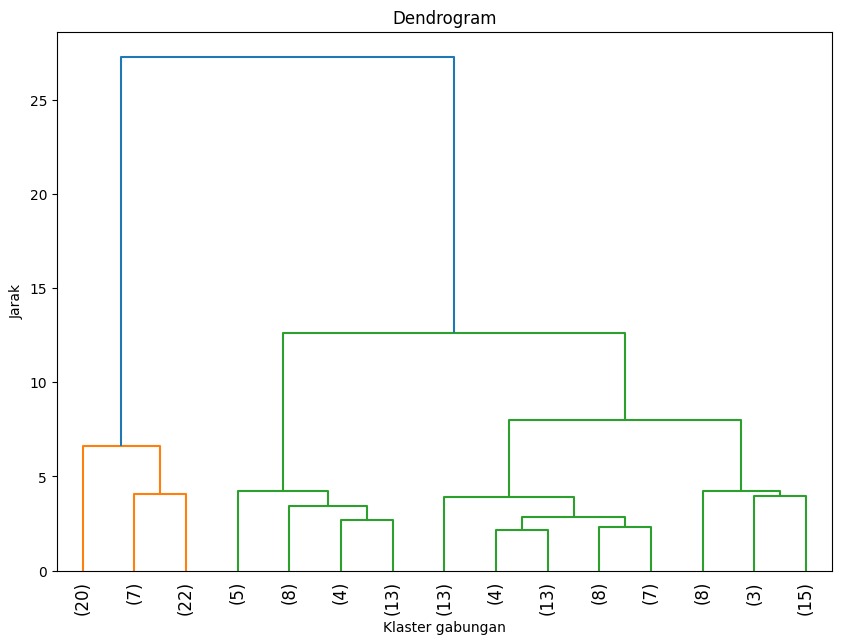

In [38]:
z = linkage(x_scaled, method='ward', metric='euclidean')
plt.figure(figsize=(10, 7))
dendrogram(z, leaf_rotation=90, truncate_mode='lastp', p=15, show_leaf_counts=True)
plt.xlabel('Klaster gabungan')
plt.ylabel('Jarak')
plt.title('Dendrogram')
plt.show()

### 4.2 Menentukan Titik Potong (max_d)

Opsional: menyorot garis potong pada ketinggian tertentu (`max_d`) untuk menunjukkan bagaimana K ditentukan dari dendrogram secara visual.

Ketinggian merge untuk membentuk k_target=4 klaster: 6.6078
Ketinggian merge berikutnya: 8.0047
Maksimum jarak merge: 7.3063


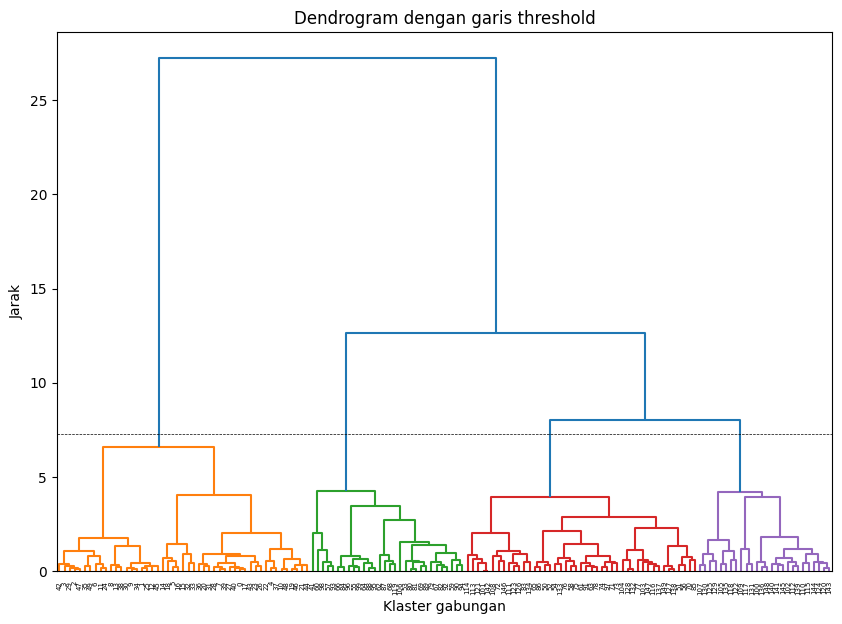

In [55]:
k_target = 4
n = x_scaled.shape[0]
idx_masuk_k = n - k_target - 1
idx_keluar_k = idx_masuk_k + 1
max_d = (z[idx_masuk_k, 2] + z[idx_keluar_k, 2]) / 2
print(f'Ketinggian merge untuk membentuk k_target={k_target} klaster: {z[idx_masuk_k, 2]:.4f}')
print(f'Ketinggian merge berikutnya: {z[idx_keluar_k, 2]:.4f}')
print(f'Maksimum jarak merge: {max_d:.4f}')

plt.figure(figsize=(10, 7))
dendrogram(z, show_leaf_counts=True, color_threshold=max_d)
plt.axhline(y=max_d, c='k', ls='--', lw=0.5)
plt.xlabel('Klaster gabungan')
plt.ylabel('Jarak')
plt.title('Dendrogram dengan garis threshold')
plt.show()

### 4.3 Bandingkan Dendrogram Keempat Linkage (Ward vs Single vs Complete vs Average)

Bangun dendrogram untuk `ward`, `single`, `complete`, dan `average` sekaligus dalam 1 grid 2x2 (`plt.subplots(2, 2)`), lalu bandingkan bentuk percabangannya secara visual.

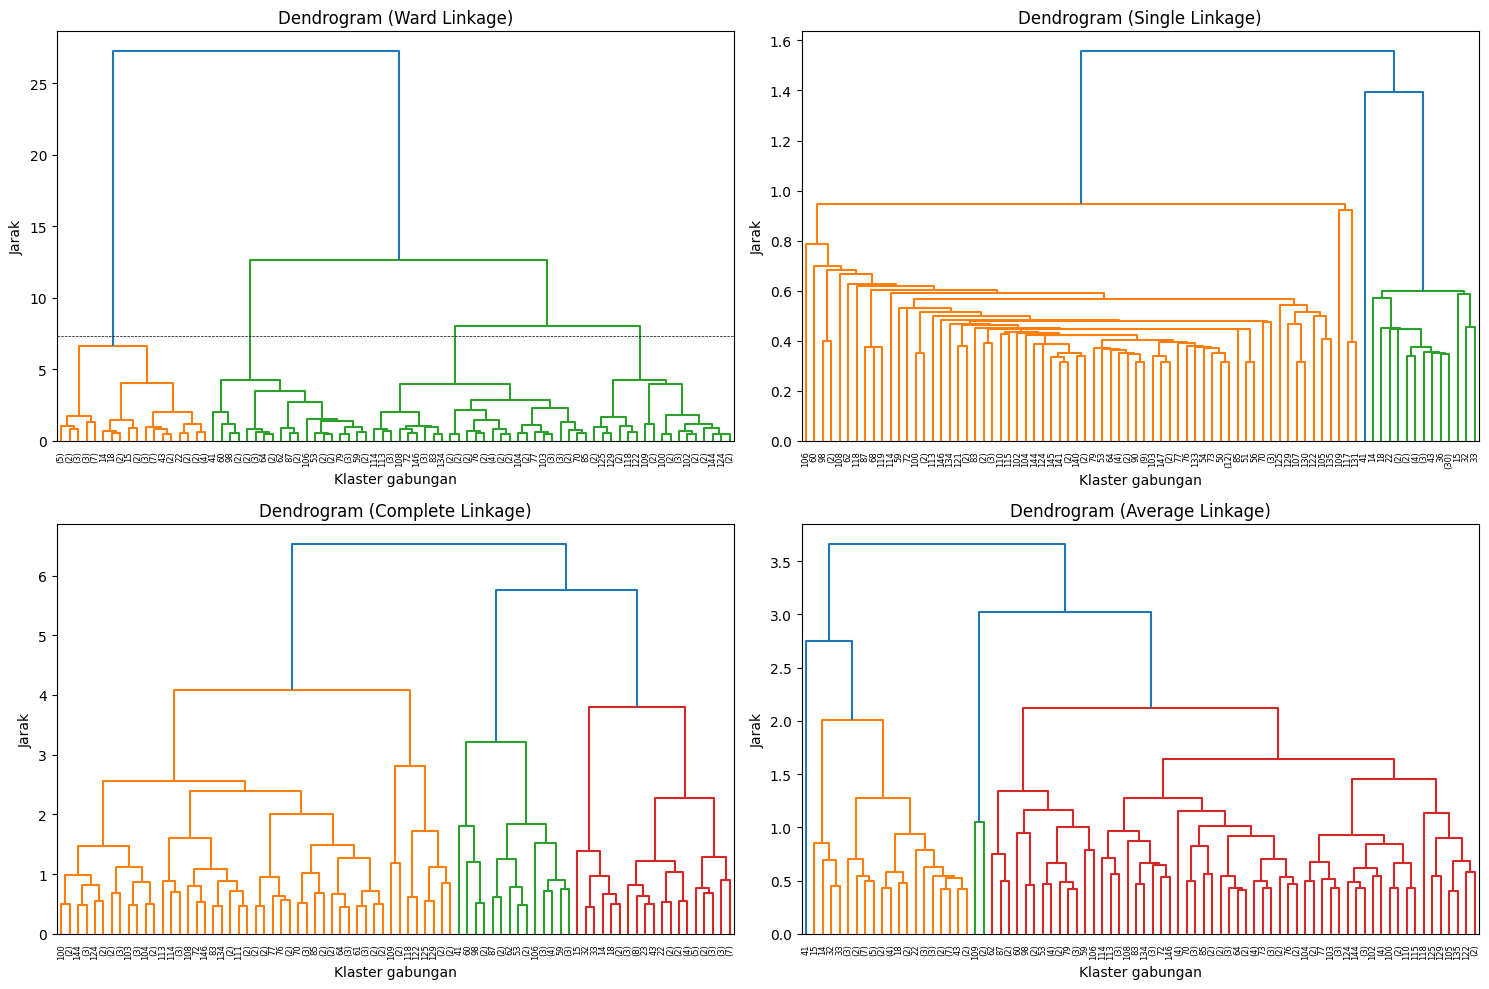

In [61]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.ravel()

for ax, mothod in zip(axes, ['ward', 'single', 'complete', 'average']):
    z_m = linkage(x_scaled, method=mothod, metric='euclidean')
    dendrogram(z_m, ax=ax, leaf_rotation=90, truncate_mode='lastp', p=80, show_leaf_counts=True)
    ax.set_title(f'Dendrogram ({mothod.capitalize()} Linkage)')
    ax.set_xlabel('Klaster gabungan')
    ax.set_ylabel('Jarak')
    ax.axhline(y=max_d, c='k', ls='--', lw=0.5)

plt.tight_layout()
plt.show()

Hitung ukuran (jumlah anggota) tiap cluster untuk `n_clusters=3` pada keempat linkage tersebut (gunakan `metric="euclidean"` untuk semuanya supaya adil dibandingkan). Identifikasi linkage mana yang menghasilkan cluster paling timpang (indikasi *chaining*).

---
## 5. Evaluasi Dendrogram Menggunakan Cophenetic Correlation Coefficient

Hitung Cophenetic Correlation Coefficient untuk linkage `ward`, lalu bandingkan dengan `average`, `complete`, dan `single`.

In [63]:
coph_corr, coph_dists = cophenet(z, pdist(x_scaled))
print(f'Korelasi cophenetic: {coph_corr:.4f}')

for method in ['ward', 'single', 'complete', 'average']:
    z_m = linkage(x_scaled, method=method, metric='euclidean')
    coph_corr_m, _ = cophenet(z_m, pdist(x_scaled))
    print(f'Korelasi cophenetic untuk {method.capitalize()} linkage: {coph_corr_m:.4f}')

Korelasi cophenetic: 0.8226
Korelasi cophenetic untuk Ward linkage: 0.8226
Korelasi cophenetic untuk Single linkage: 0.8300
Korelasi cophenetic untuk Complete linkage: 0.7515
Korelasi cophenetic untuk Average linkage: 0.8544


---
## 6. Heatmap

Visualisasikan seluruh fitur (dalam skala z-score) untuk semua sampel, diurutkan berdasarkan cluster hasil linkage `ward`.

---
## 7. Catatan Penting Praktikum

- Standardisasi WAJIB sebelum Agglomerative Clustering.
- `linkage="ward"` HARUS dipasangkan dengan `metric="euclidean"`.
- Beda linkage bisa menghasilkan cluster yang berbeda pada K yang sama — bandingkan minimal 2 metrik evaluasi (Silhouette Score DAN Cophenetic Correlation Coefficient) sebelum memilih linkage terbaik.
- Cophenetic Correlation Coefficient dan Silhouette Score mengukur hal berbeda (struktur pohon vs kualitas potongan) — sepakat di satu dataset bukan jaminan akan selalu sepakat di dataset lain.

---
## 8. Latihan

Ganti dataset ke Wine (`sklearn.datasets.load_wine`).

1. Jalankan `AgglomerativeClustering` untuk `n_clusters = 3` dengan `linkage = ["ward", "average", "complete", "single"]`. Catat Silhouette Score tiap kombinasi.
2. Bangun dendrogram untuk `method="ward"` dan tentukan jumlah cluster yang wajar dari ketinggian merge yang besar.
3. Buat heatmap z-score fitur yang diurutkan menurut label cluster terbaik.
4. Bandingkan hasil Ward vs Average: mana yang menghasilkan cluster lebih seimbang? Dukung dengan Silhouette Score dan visualisasi.
5. (Opsional) Coba `metric` lain (mis. `cosine`) untuk linkage non-Ward dan diskusikan dampaknya pada bentuk cluster/score.
6. Hitung Cophenetic Correlation Coefficient untuk tiap metode linkage yang dicoba di poin 1. Apakah metode dengan Silhouette Score tertinggi juga memiliki koefisien kophenetik tertinggi? Jelaskan kemungkinan penyebabnya jika jawabannya tidak.